# OIBSIP – Task 1: EDA on Retail Sales Data

**Track:** Data Analytics  |  **Level:** Level 1  

This notebook explores a practice retail dataset. The included CSV is synthetic (created for learning), not real company/customer data.

## 1. Import libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
print('Libraries imported successfully!')

Libraries imported successfully!


## 2. Load the dataset

In [5]:
df = pd.read_csv('dataset/retail_sales.csv')
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Product,Quantity,Price per Unit,Total Amount
0,T0144,2025-01-02,C019,Female,24.0,Electronics,Smartwatch,4,4228,16912
1,T0106,2025-01-03,C078,Male,18.0,Electronics,Keyboard,1,1222,1222
2,T0199,2025-01-03,C051,Male,31.0,Electronics,Mouse,1,631,631
3,T0146,2025-01-04,C055,Female,43.0,Clothing,Jacket,2,3512,7024
4,T0180,2025-01-08,C068,Other,23.0,Electronics,Keyboard,4,1252,5008


## 3. Understand the data

In [6]:
print('Shape:', df.shape)
print('\nColumns:', df.columns.tolist())
df.info()

Shape: (250, 10)

Columns: ['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Product', 'Quantity', 'Price per Unit', 'Total Amount']
<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    250 non-null    str    
 1   Date              250 non-null    str    
 2   Customer ID       250 non-null    str    
 3   Gender            249 non-null    str    
 4   Age               248 non-null    float64
 5   Product Category  250 non-null    str    
 6   Product           250 non-null    str    
 7   Quantity          250 non-null    int64  
 8   Price per Unit    250 non-null    int64  
 9   Total Amount      250 non-null    int64  
dtypes: float64(1), int64(3), str(6)
memory usage: 19.7 KB


In [7]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              1
Age                 2
Product Category    0
Product             0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [8]:
df.describe()

,Age,Quantity,Price per Unit,Total Amount
count,248.000000,250.000000,250.000000,250.000000
mean,33.254032,2.472000,1616.864000,3814.772000
std,10.114926,1.144752,1104.026307,3330.806941
min,18.000000,1.000000,307.000000,324.000000
25%,26.000000,1.000000,696.000000,1503.000000
50%,33.000000,2.000000,1286.500000,2780.000000
75%,40.000000,4.000000,2225.500000,4854.750000
max,66.000000,4.000000,5147.000000,19180.000000


## 4. Prepare date and time fields

In [9]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df['Month'] = df['Date'].dt.to_period('M').astype(str)
df['Quarter'] = df['Date'].dt.to_period('Q').astype(str)
df[['Date', 'Month', 'Quarter']].head()

,Date,Month,Quarter
0,2025-01-02,2025-01,2025Q1
1,2025-01-03,2025-01,2025Q1
2,2025-01-03,2025-01,2025Q1
3,2025-01-04,2025-01,2025Q1
4,2025-01-08,2025-01,2025Q1


## 5. Monthly and quarterly sales trends

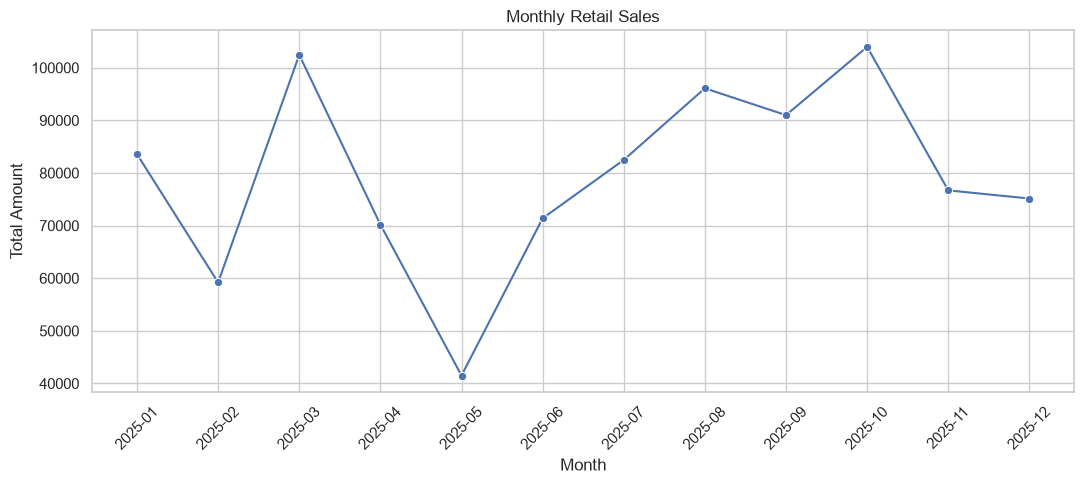

In [10]:
monthly_sales = df.groupby('Month', as_index=False)['Total Amount'].sum()
plt.figure(figsize=(11,5))
sns.lineplot(data=monthly_sales, x='Month', y='Total Amount', marker='o')
plt.title('Monthly Retail Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

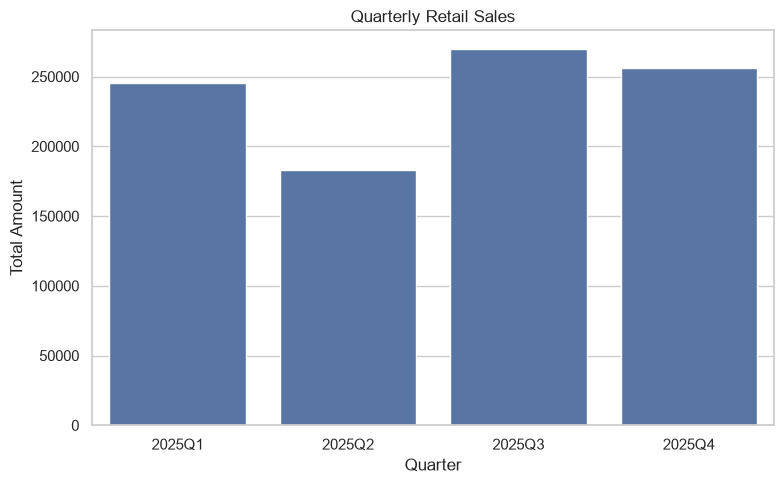

In [11]:
quarterly_sales = df.groupby('Quarter', as_index=False)['Total Amount'].sum()
plt.figure(figsize=(8,5))
sns.barplot(data=quarterly_sales, x='Quarter', y='Total Amount')
plt.title('Quarterly Retail Sales')
plt.tight_layout()
plt.show()

**Observation prompt:** Which month or quarter has the highest sales? Check whether it could be linked to promotions, holidays or stock availability.

## 6. Customer age group and gender

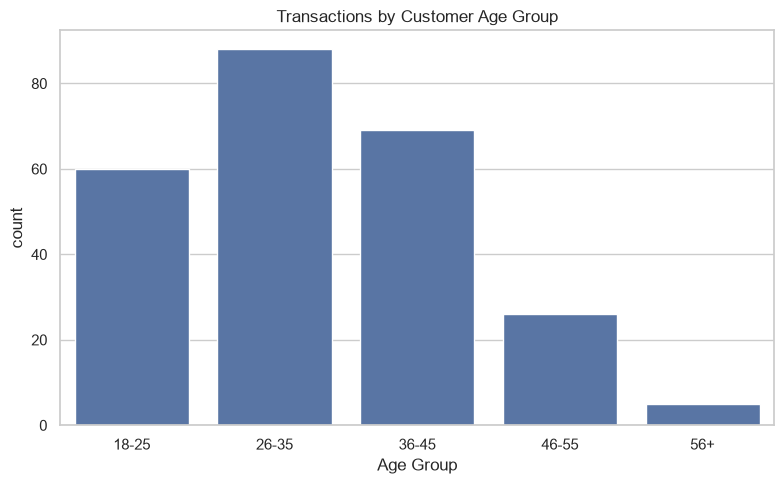

In [12]:
age_data = df.dropna(subset=['Age']).copy()
age_data['Age Group'] = pd.cut(age_data['Age'], bins=[17,25,35,45,55,100], labels=['18-25','26-35','36-45','46-55','56+'])
plt.figure(figsize=(8,5))
sns.countplot(data=age_data, x='Age Group')
plt.title('Transactions by Customer Age Group')
plt.tight_layout()
plt.show()

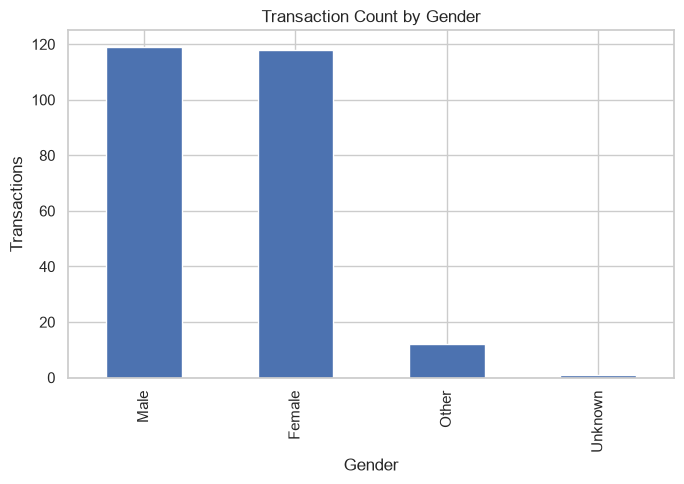

In [13]:
plt.figure(figsize=(7,5))
df['Gender'].fillna('Unknown').value_counts().plot(kind='bar')
plt.title('Transaction Count by Gender')
plt.xlabel('Gender'); plt.ylabel('Transactions')
plt.tight_layout(); plt.show()

**Observation prompt:** Which age group has the most transactions? Is the gender split balanced?

## 7. Top 10 products and revenue by category

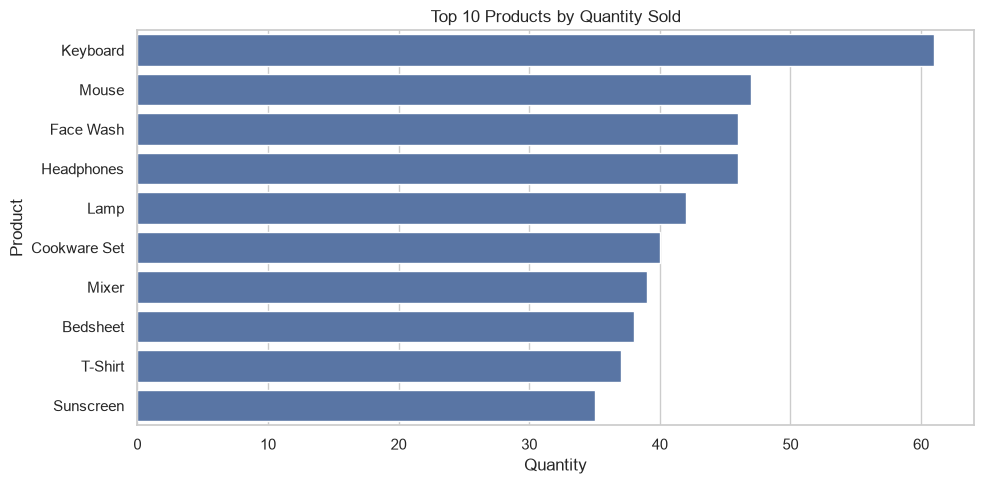

In [14]:
top_products = df.groupby('Product', as_index=False)['Quantity'].sum().nlargest(10, 'Quantity')
plt.figure(figsize=(10,5))
sns.barplot(data=top_products, y='Product', x='Quantity')
plt.title('Top 10 Products by Quantity Sold')
plt.tight_layout(); plt.show()

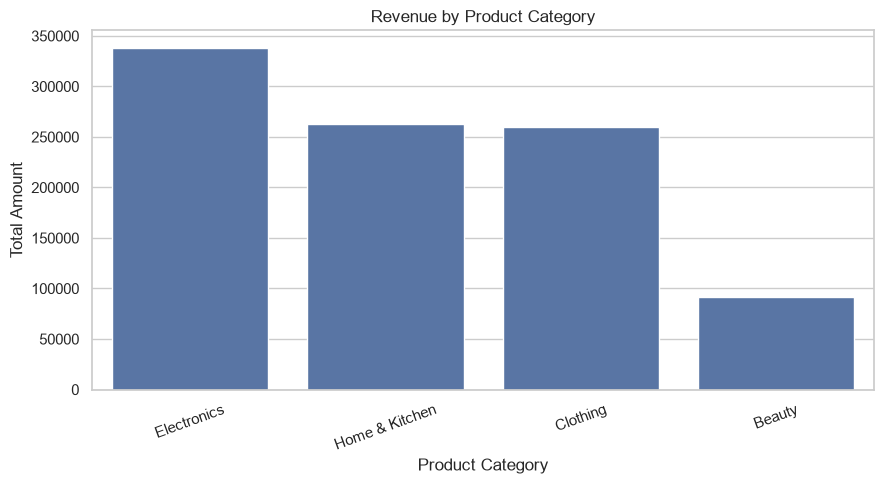

,Product Category,Total Amount
2,Electronics,338452
3,Home & Kitchen,263039
1,Clothing,260312
0,Beauty,91890


In [15]:
category_revenue = df.groupby('Product Category', as_index=False)['Total Amount'].sum().sort_values('Total Amount', ascending=False)
plt.figure(figsize=(9,5))
sns.barplot(data=category_revenue, x='Product Category', y='Total Amount')
plt.title('Revenue by Product Category')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()
category_revenue

## 8. Correlation heatmap

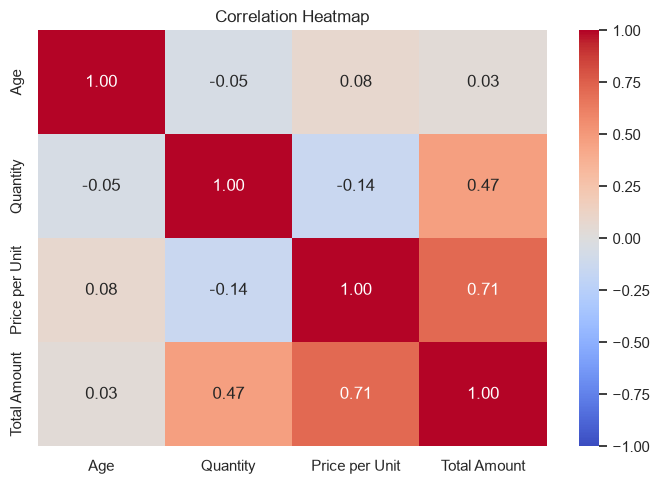

In [16]:
numeric_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
correlation = df[numeric_cols].corr(numeric_only=True)
plt.figure(figsize=(7,5))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.tight_layout(); plt.show()

## 9. Extra analysis: revenue by gender

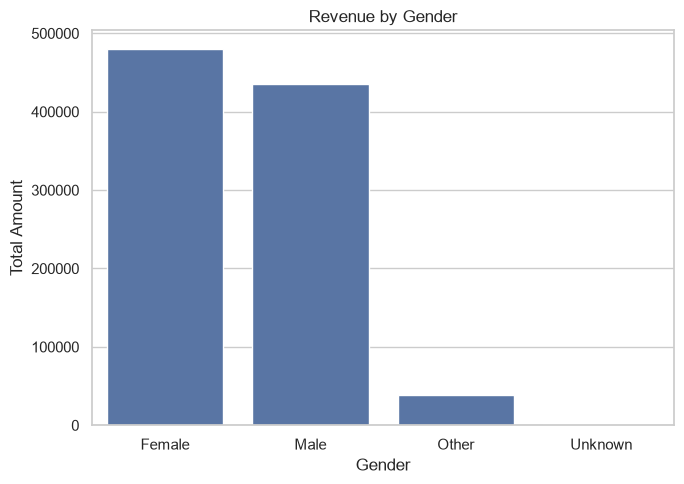

In [17]:
gender_revenue = df.groupby('Gender', dropna=False)['Total Amount'].sum().reset_index()
gender_revenue['Gender'] = gender_revenue['Gender'].fillna('Unknown')
plt.figure(figsize=(7,5))
sns.barplot(data=gender_revenue, x='Gender', y='Total Amount')
plt.title('Revenue by Gender')
plt.tight_layout(); plt.show()

## 10. Clean missing values and export

In [18]:
clean_df = df.copy()
clean_df['Age'] = clean_df['Age'].fillna(clean_df['Age'].median())
clean_df['Gender'] = clean_df['Gender'].fillna('Unknown')
clean_df.to_csv('outputs/retail_sales_cleaned.csv', index=False)
print('Cleaned file saved in outputs/retail_sales_cleaned.csv')
print(clean_df.isnull().sum())

Cleaned file saved in outputs/retail_sales_cleaned.csv
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Product             0
Quantity            0
Price per Unit      0
Total Amount        0
Month               0
Quarter             0
dtype: int64


## 11. Business recommendations

Use the charts and your own findings to write at least three recommendations. Examples to validate against the outputs:

1. Prioritise replenishment of popular products and the strongest revenue category.
2. Plan promotions around months/quarters with lower sales, after checking seasonality and stock availability.
3. Test product bundles or cross-selling to improve average transaction value.
4. Improve customer data capture to reduce missing demographic values.

## 12. Save your work

Run all cells from top to bottom. Save the notebook, then include screenshots of key outputs in the `screenshots` folder for your submission.